# Proyecto: Retención de clientes en Interconnect

## Objetivo general

El operador de telecomunicaciones Interconnect quiere saber con anticipación qué clientes planean darse de baja, para ofrecerles códigos promocionales y planes especiales antes de que se vayan. Retener a un cliente actual es más barato que conseguir uno nuevo, pero hoy el equipo de marketing no sabe a quién dirigir esas promociones.

En este proyecto voy a construir un modelo de clasificación que responda a la pregunta: ¿este cliente se dará de baja pronto, sí o no?

## Descripción de los datos

Los datos vienen en cuatro archivos y todos comparten la columna `customerID`, que identifica a cada cliente:

- `contract.csv`: información del contrato, con fechas de inicio y fin, tipo de contrato, facturación, método de pago y cargos.
- `personal.csv`: datos demográficos del cliente.
- `internet.csv`: servicios de internet contratados, como fibra óptica, DSL, antivirus o soporte técnico.
- `phone.csv`: servicios telefónicos, en concreto si el cliente tiene varias líneas.

No existe una columna que indique la baja. El estado del cliente se deduce de `EndDate`: si tiene una fecha, el cliente se fue, y si dice "No", el cliente sigue activo.

## 1. Carga y exploración de los datos

**Objetivo**

Conocer cada una de las cuatro tablas antes de unirlas: cuántas filas y columnas tiene, qué tipo de dato guarda cada columna y qué problemas habrá que corregir en la siguiente etapa. En esta etapa solo reviso los datos, todavía no modifico nada.

In [1]:
# importamos pandas para cargar y revisar las tablas
import pandas as pd

# importamos matplotlib para las gráficas
import matplotlib.pyplot as plt

# importamos las herramientas de sklearn para dividir, escalar, entrenar y evaluar
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score, accuracy_score
from sklearn.metrics import precision_score, confusion_matrix, roc_curve

# importamos LightGBM para el modelo de potenciación del gradiente
from lightgbm import LGBMClassifier

In [2]:
# ahora vamos a crear una función que carga un archivo,
# primero busca el archivo junto al notebook y si no está usa la ruta de la plataforma
def cargar_datos(nombre_archivo):
    try:
        datos = pd.read_csv(nombre_archivo)  # ruta local
    except FileNotFoundError:
        datos = pd.read_csv('/datasets/final_provider/' + nombre_archivo)  # ruta de la plataforma
    return datos

In [3]:
# ahora vamos a cargar cada archivo en su propio DataFrame
contrato = cargar_datos('contract.csv')
personal = cargar_datos('personal.csv')
internet = cargar_datos('internet.csv')
telefono = cargar_datos('phone.csv')

### 1.1 Tabla de contratos

In [4]:
# ahora vamos a ver las primeras filas de la tabla
contrato.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [5]:
# ahora vamos a revisar las columnas, los tipos de dato y los valores no nulos
contrato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


### 1.2 Tabla de datos personales

In [6]:
# ahora vamos a ver las primeras filas de la tabla
personal.head()

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [7]:
# ahora vamos a revisar las columnas, los tipos de dato y los valores no nulos
personal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB


### 1.3 Tabla de servicios de internet

In [8]:
# ahora vamos a ver las primeras filas de la tabla
internet.head()

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


In [9]:
# ahora vamos a revisar las columnas, los tipos de dato y los valores no nulos
internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


### 1.4 Tabla de servicios telefónicos

In [10]:
# ahora vamos a ver las primeras filas de la tabla
telefono.head()

,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [11]:
# ahora vamos a revisar las columnas, los tipos de dato y los valores no nulos
telefono.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


### 1.5 Comprobaciones adicionales

In [12]:
# ahora vamos a revisar en cada tabla las filas duplicadas y los clientes únicos
tablas = [contrato, personal, internet, telefono]
nombres = ['contrato', 'personal', 'internet', 'telefono']

for i, tabla in enumerate(tablas):
    print(nombres[i])
    print('  filas:', len(tabla))
    print('  filas duplicadas:', tabla.duplicated().sum())
    print('  clientes únicos:', tabla['customerID'].nunique())

contrato
  filas: 7043
  filas duplicadas: 0
  clientes únicos: 7043
personal
  filas: 7043
  filas duplicadas: 0
  clientes únicos: 7043
internet
  filas: 5517
  filas duplicadas: 0
  clientes únicos: 5517
telefono
  filas: 6361
  filas duplicadas: 0
  clientes únicos: 6361


In [13]:
# ahora vamos a ver qué valores toma EndDate, la columna de la que saldrá el objetivo
contrato['EndDate'].value_counts()

EndDate
No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: count, dtype: int64

In [14]:
# TotalCharges aparece como texto en info(), así que buscamos los valores que no son números
cargos_vacios = contrato[contrato['TotalCharges'] == ' ']
print('Filas con TotalCharges vacío:', len(cargos_vacios))
cargos_vacios[['customerID', 'BeginDate', 'EndDate', 'MonthlyCharges', 'TotalCharges']]

Filas con TotalCharges vacío: 11


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,52.55,
753,3115-CZMZD,2020-02-01,No,20.25,
936,5709-LVOEQ,2020-02-01,No,80.85,
1082,4367-NUYAO,2020-02-01,No,25.75,
1340,1371-DWPAZ,2020-02-01,No,56.05,
3331,7644-OMVMY,2020-02-01,No,19.85,
3826,3213-VVOLG,2020-02-01,No,25.35,
4380,2520-SGTTA,2020-02-01,No,20.00,
5218,2923-ARZLG,2020-02-01,No,19.70,
6670,4075-WKNIU,2020-02-01,No,73.35,


In [15]:
# ahora vamos a ver el rango de fechas de inicio de contrato
print('Primera fecha de inicio:', contrato['BeginDate'].min())
print('Última fecha de inicio:', contrato['BeginDate'].max())

Primera fecha de inicio: 2013-10-01
Última fecha de inicio: 2020-02-01


**Conclusión**

Se crea 1 DataFrame para cada tabla y las revisamos sin hacer modificaciones. Hago un listado de hallazgos:

- `contrato` y `personal` tienen 7043 filas cada una, una por cliente. `internet` tiene 5517 filas y `telefono` 6361, porque no todos los clientes contratan los dos servicios. Al unir las tablas van a quedar unos clientes sin registro de uso de internet y 682 sin el de teléfono. Esos nulos significan que el cliente no tiene el servicio, no que falte información.
- Ninguna tabla tiene filas duplicadas ni valores nulos, y en todas el `customerID` es único, así que la unión por esa columna no va a repetir clientes.
- En `contrato`, las columnas `BeginDate`, `EndDate` y `TotalCharges` están guardadas como texto. Las fechas se deben convertir a fecha y `TotalCharges` a número.
- `TotalCharges` tiene 11 valores vacíos. Los 11 son clientes que empezaron el 2020-02-01, la última fecha de inicio de los datos, y siguen activos. Todavía no acumulan cargos, por eso el campo está vacío.
- `EndDate` dice "No" en 5174 clientes, que son los activos. Los otros 1869 tienen fecha de baja, lo que equivale al 26.5 % del total. Todas las bajas caen en solo cuatro meses, de octubre de 2019 a enero de 2020, con entre 458 y 485 bajas por mes.
- Casi todas las columnas son categóricas con valores "Yes" y "No" o con pocas categorías, así que habrá que codificarlas antes de entrenar el modelo. `SeniorCitizen` es la excepción, ya viene como 0 y 1.

En la siguiente etapa corrijo los tipos de dato, uno las cuatro tablas y creo la variable objetivo a partir de `EndDate`.

## 2. Preprocesamiento y unión de las tablas

**Objetivo**

Dejar una sola tabla lista para analizar. Para eso se deben corregir los tipos de dato que no cuadran. Además debo la variable objetivo a partir de `EndDate`, calculo la antigüedad de cada cliente, uno las cuatro tablas y trato los nulos que aparecen en los clientes que no contrataron internet o teléfono.

La codificación de las columnas categóricas la dejo para la etapa de modelado, porque en el análisis exploratorio es más fácil agrupar y graficar con las categorías originales.

### 2.1 Corrección de `TotalCharges`

In [16]:
# Vamos a convertir TotalCharges a número,
# los valores que no son números (los espacios vacíos) quedan como nulos
contrato['TotalCharges'] = pd.to_numeric(contrato['TotalCharges'], errors='coerce')
print('Nulos después de convertir:', contrato['TotalCharges'].isna().sum())

Nulos después de convertir: 11


In [17]:
# Rellenamos esos nulos con 0, porque son clientes que todavía no tienen cargos
contrato['TotalCharges'] = contrato['TotalCharges'].fillna(0)
print('Nulos después de rellenar:', contrato['TotalCharges'].isna().sum())
print('Tipo de dato:', contrato['TotalCharges'].dtype)

Nulos después de rellenar: 0
Tipo de dato: float64


### 2.2 Variable objetivo

In [18]:
# Creamos la columna objetivo: 1 si el cliente se dio de baja y 0 si sigue activo
contrato['baja'] = 0
contrato.loc[contrato['EndDate'] != 'No', 'baja'] = 1

print(contrato['baja'].value_counts())
print('Proporción de bajas:', round(contrato['baja'].mean(), 3))

baja
0    5174
1    1869
Name: count, dtype: int64
Proporción de bajas: 0.265


### 2.3 Fechas y antigüedad del cliente

In [19]:
# Convertimos la fecha de inicio a tipo fecha
contrato['BeginDate'] = pd.to_datetime(contrato['BeginDate'], format='%Y-%m-%d')

# a los clientes activos les ponemos la fecha de corte (2020-02-01) en lugar de "No",
# porque es el último día con datos y hasta ahí medimos su antigüedad
contrato['fecha_fin'] = contrato['EndDate'].replace('No', '2020-02-01 00:00:00')
contrato['fecha_fin'] = pd.to_datetime(contrato['fecha_fin'], format='%Y-%m-%d %H:%M:%S')

contrato[['BeginDate', 'EndDate', 'fecha_fin']].head()

,BeginDate,EndDate,fecha_fin
0,2020-01-01,No,2020-02-01
1,2017-04-01,No,2020-02-01
2,2019-10-01,2019-12-01 00:00:00,2019-12-01
3,2016-05-01,No,2020-02-01
4,2019-09-01,2019-11-01 00:00:00,2019-11-01


In [20]:
# Ahora calculamos la antigüedad en meses, desde el inicio hasta la baja o hasta la fecha de corte
anios = contrato['fecha_fin'].dt.year - contrato['BeginDate'].dt.year
meses = contrato['fecha_fin'].dt.month - contrato['BeginDate'].dt.month
contrato['antiguedad_meses'] = anios * 12 + meses

print('Antigüedad mínima:', contrato['antiguedad_meses'].min())
print('Antigüedad máxima:', contrato['antiguedad_meses'].max())
print('Antigüedad media:', round(contrato['antiguedad_meses'].mean(), 1))
print('Clientes con antigüedad 0:', (contrato['antiguedad_meses'] == 0).sum())

Antigüedad mínima: 0
Antigüedad máxima: 72
Antigüedad media: 32.4
Clientes con antigüedad 0: 11


### 2.4 Unión de las tablas

In [21]:
# ahora vamos a unir las cuatro tablas por customerID,
# usamos how='left' para conservar a todos los clientes de la tabla de contratos
datos = contrato.merge(personal, on='customerID', how='left')
datos = datos.merge(internet, on='customerID', how='left')
datos = datos.merge(telefono, on='customerID', how='left')

print('Filas y columnas:', datos.shape)
print('Clientes únicos:', datos['customerID'].nunique())

Filas y columnas: (7043, 23)
Clientes únicos: 7043


In [22]:
# ahora contemos los nulos que dejó la unión en cada columna
datos.isna().sum()

customerID             0
BeginDate              0
EndDate                0
Type                   0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
baja                   0
fecha_fin              0
antiguedad_meses       0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64

### 2.5 Nulos de los servicios no contratados

In [23]:
# antes de rellenar, guardamos en una columna si el cliente tiene servicio de teléfono,
# porque después del relleno ya no se puede distinguir
datos['tiene_telefono'] = 1
datos.loc[datos['MultipleLines'].isna(), 'tiene_telefono'] = 0

print(datos['tiene_telefono'].value_counts())

tiene_telefono
1    6361
0     682
Name: count, dtype: int64


In [24]:
# ahora vamos a rellenar con 'No' los nulos de las columnas de servicios
columnas_servicios = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                      'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']

for columna in columnas_servicios:
    datos[columna] = datos[columna].fillna('No')

print('Nulos en toda la tabla:', datos.isna().sum().sum())

Nulos en toda la tabla: 0


In [25]:
# ahora vamos a comprobar cómo quedaron las dos columnas que indican el servicio contratado
print(datos['InternetService'].value_counts())
print()
print(datos['MultipleLines'].value_counts())

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64


In [26]:
# por último revisamos con info() la tabla definitiva
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           7043 non-null   object        
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   baja              7043 non-null   int64         
 9   fecha_fin         7043 non-null   datetime64[ns]
 10  antiguedad_meses  7043 non-null   int32         
 11  gender            7043 non-null   object        
 12  SeniorCitizen     7043 non-null   int64         
 13  Partner           7043 non-null   object        
 14  Dependents        7043 n

**Conclusión**

Terminé con una sola tabla, `datos`, de 7043 filas y 24 columnas, un cliente por fila y sin ningún nulo. A continuación resumo el principal razonamiento realizado para tomar decisiones:

- `TotalCharges` tenía 11 valores vacíos, que al convertir la columna a número quedaron como nulos. Decidí rellenarlos con 0 en lugar de borrar las filas. Son clientes que empezaron el 2020-02-01, el mismo día del corte de los datos, así que 0 es su cargo real y no un valor inventado. Borrarlos habría quitado a los clientes más nuevos sin razón.
- Creé la variable objetivo `baja` a partir de `EndDate`: 1 si el contrato tiene fecha de fin y 0 si dice "No". Quedaron 1869 bajas y 5174 clientes activos, es decir, el 26.5 % de los clientes se dio de baja. Las clases están desbalanceadas y lo voy a tener en cuenta al entrenar y al elegir las métricas.
- Calculé `antiguedad_meses` como los meses entre el inicio del contrato y la baja, y para los clientes activos hasta el 2020-02-01, que es la fecha de corte. No medí a todos hasta la fecha de corte porque a un cliente que se fue antes de la fecha de corte de los datos le estaría contando meses en los que ya no era cliente. La antigüedad va de 0 a 72 meses, con una media de 32.4, y los 11 clientes con antigüedad 0 son los mismos que tenían `TotalCharges` vacío.
- Uní las tablas con `how='left'` partiendo de `contrato`, para conservar a todos los clientes aunque no tengan alguno de los servicios. Después de la unión siguen siendo 7043 clientes únicos, así que no se perdió ni se repitió ninguno.
- La unión dejó nulos en 1526 clientes en las siete columnas de internet y en 682 clientes en `MultipleLines`. No son errores, son clientes que no contrataron ese servicio, así que los rellené con "No".
- Antes de rellenar creé la columna `tiene_telefono`. La razón es que `MultipleLines` solo dice si el cliente tiene varias líneas, y al rellenar con "No" quedan juntos dos grupos distintos: los 3390 clientes que tienen teléfono con una sola línea y los 682 que no tienen teléfono, que suman los 4072 "No" de la columna. Sin `tiene_telefono` el modelo no podría diferenciarlos. Quedaron 6361 clientes con teléfono y 682 sin teléfono.
- Para internet no hizo falta una columna parecida, porque `InternetService` ya lo indica: después del relleno tiene tres valores, fibra óptica con 3096 clientes, DSL con 2421 y "No" con 1526.

Dejé en la tabla `customerID`, `BeginDate`, `EndDate` y `fecha_fin` porque las fechas me sirven para el análisis exploratorio. Las elimino en la etapa de modelado, ya que `EndDate` y `fecha_fin` contienen la respuesta que el modelo tiene que predecir, dejarlas sería sesgar el entrenamiento.

## 3. Análisis exploratorio

**Objetivo**

Entender el estado de la compañía respecto a sus clientes y encontrar qué características separan a los clientes que se dan de baja de los que se quedan. Primero comparo las bajas con las altas por mes, y después reviso la tasa de baja según la antigüedad, los cargos, el contrato, los servicios y los datos personales. Lo que encuentre aquí me sirve para saber qué columnas pueden ayudar al modelo.

### 3.1 Bajas y altas por mes

In [27]:
# Contamos las bajas de cada mes usando la fecha de fin de los clientes que se fueron
solo_bajas = datos[datos['baja'] == 1]
bajas_mes = solo_bajas.groupby('fecha_fin')['customerID'].count()

# ahora contamos las altas de cada mes y nos quedamos con los mismos meses en los que hay bajas
altas_mes = datos.groupby('BeginDate')['customerID'].count()
altas_mes = altas_mes.loc[bajas_mes.index]

movimiento = pd.DataFrame({'altas': altas_mes, 'bajas': bajas_mes})
movimiento['saldo'] = movimiento['altas'] - movimiento['bajas']
print(movimiento)
print()
print('Promedio de altas por mes:', round(movimiento['altas'].mean(), 1))
print('Promedio de bajas por mes:', round(movimiento['bajas'].mean(), 1))

            altas  bajas  saldo
fecha_fin                      
2019-10-01    237    458   -221
2019-11-01    237    485   -248
2019-12-01    220    466   -246
2020-01-01    233    460   -227

Promedio de altas por mes: 231.8
Promedio de bajas por mes: 467.2


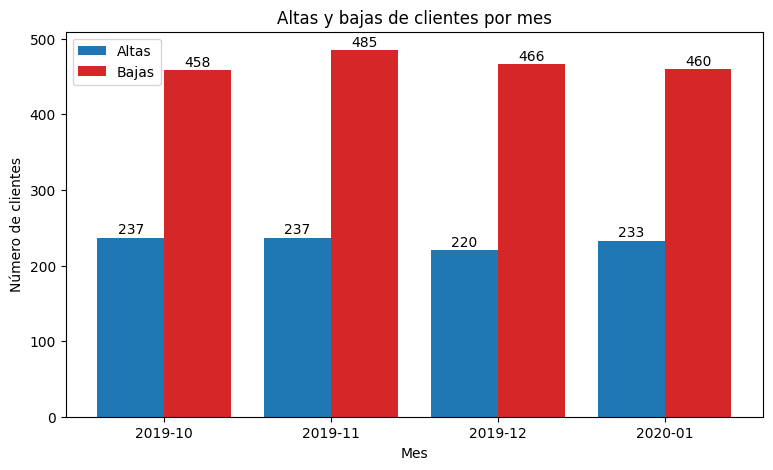

In [28]:
# ahora vamos a graficar las altas y las bajas de cada mes, una barra al lado de la otra
etiquetas = []
for fecha in movimiento.index:
    etiquetas.append(fecha.strftime('%Y-%m'))

posiciones_altas = []
posiciones_bajas = []
for i in range(len(movimiento)):
    posiciones_altas.append(i - 0.2)
    posiciones_bajas.append(i + 0.2)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(posiciones_altas, movimiento['altas'], width=0.4, label='Altas', color='tab:blue')
ax.bar(posiciones_bajas, movimiento['bajas'], width=0.4, label='Bajas', color='tab:red')

# escribimos el valor encima de cada barra
for i in range(len(movimiento)):
    ax.text(posiciones_altas[i], movimiento['altas'].iloc[i] + 5, str(movimiento['altas'].iloc[i]), ha='center')
    ax.text(posiciones_bajas[i], movimiento['bajas'].iloc[i] + 5, str(movimiento['bajas'].iloc[i]), ha='center')

ax.set_xticks(range(len(movimiento)))
ax.set_xticklabels(etiquetas)
ax.set_title('Altas y bajas de clientes por mes')
ax.set_xlabel('Mes')
ax.set_ylabel('Número de clientes')
ax.legend()
plt.show()

### 3.2 Antigüedad y cargo mensual

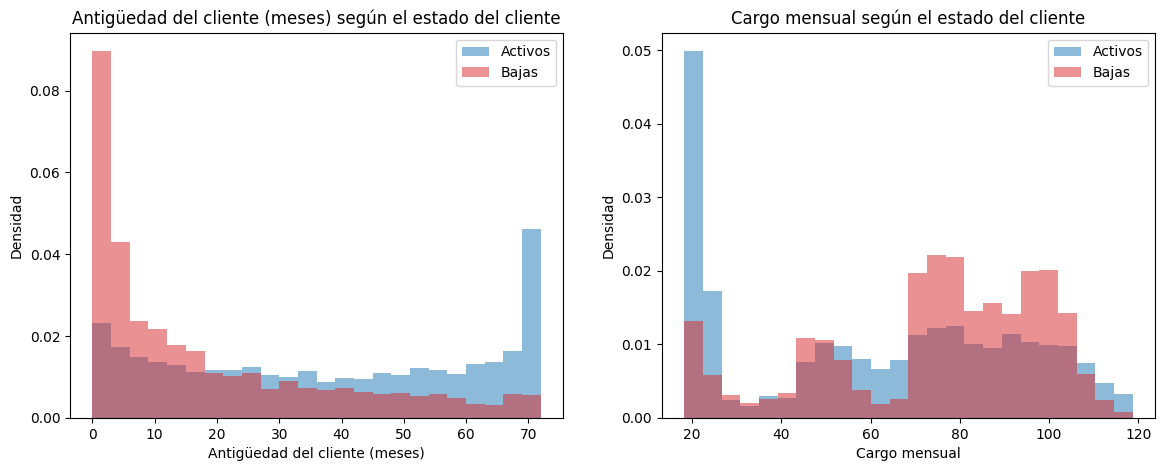

In [29]:
# ahora vamos a separar a los clientes activos de los que se dieron de baja
activos = datos[datos['baja'] == 0]
bajas = datos[datos['baja'] == 1]

columnas = ['antiguedad_meses', 'MonthlyCharges']
titulos = ['Antigüedad del cliente (meses)', 'Cargo mensual']

# usamos density=True porque hay muchos más activos que bajas,
# así cada grupo se dibuja como proporción de su propio total y se pueden comparar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, columna in enumerate(columnas):
    ax = axes[i]
    rango = (datos[columna].min(), datos[columna].max())
    ax.hist(activos[columna], bins=24, range=rango, density=True, alpha=0.5, label='Activos', color='tab:blue')
    ax.hist(bajas[columna], bins=24, range=rango, density=True, alpha=0.5, label='Bajas', color='tab:red')
    ax.set_title(titulos[i] + ' según el estado del cliente')
    ax.set_xlabel(titulos[i])
    ax.set_ylabel('Densidad')
    ax.legend()
plt.show()

In [30]:
# ahora vamos a comparar la media y la mediana de cada grupo (0 = activo, 1 = baja)
datos.groupby('baja')[['antiguedad_meses', 'MonthlyCharges']].agg(['mean', 'median']).round(1)

antiguedad_meses        MonthlyCharges       
                 mean median           mean median
baja                                              
0                37.6   38.0           61.3   64.4
1                18.0   10.0           74.4   79.6

In [31]:
# ahora vamos a comparar la tasa de baja de los clientes más nuevos con la de los más antiguos
nuevos = datos[datos['antiguedad_meses'] <= 6]
antiguos = datos[datos['antiguedad_meses'] > 48]

print('Clientes con 6 meses o menos:', len(nuevos))
print('  tasa de baja (%):', round(nuevos['baja'].mean() * 100, 1))
print('Clientes con más de 48 meses:', len(antiguos))
print('  tasa de baja (%):', round(antiguos['baja'].mean() * 100, 1))

Clientes con 6 meses o menos: 1481
  tasa de baja (%): 52.9
Clientes con más de 48 meses: 2239
  tasa de baja (%): 9.5


### 3.3 Contrato y forma de pago

In [32]:
# ahora vamos a crear una función que imprime la tasa de baja de cada categoría de una lista de columnas
def tabla_tasa_baja(columnas):
    for columna in columnas:
        resumen = datos.groupby(columna)['baja'].agg(['mean', 'count'])
        resumen['mean'] = (resumen['mean'] * 100).round(1)
        resumen.columns = ['tasa_baja_%', 'clientes']
        print(resumen)
        print()


# y otra función que dibuja esa tasa de baja, con un panel por columna
def graficar_tasa_baja(columnas, filas, paneles_por_fila, titulo):
    tasa_general = datos['baja'].mean() * 100
    fig, axes = plt.subplots(filas, paneles_por_fila, figsize=(5.5 * paneles_por_fila, 4.5 * filas))
    axes = axes.flatten()
    for i, columna in enumerate(columnas):
        ax = axes[i]
        tasa = datos.groupby(columna)['baja'].mean() * 100
        etiquetas = []
        for valor in tasa.index:
            etiquetas.append(str(valor))
        ax.bar(etiquetas, tasa.values, color='tab:red')
        # escribimos el porcentaje encima de cada barra
        for j, valor in enumerate(tasa.values):
            ax.text(j, valor + 1, str(round(valor, 1)) + ' %', ha='center')
        # línea de referencia con la tasa de baja de todos los clientes
        ax.axhline(tasa_general, color='gray', linestyle='--', label='Tasa general')
        ax.set_title(columna)
        ax.set_ylabel('Tasa de baja (%)')
        ax.set_ylim(0, 60)
        ax.tick_params(axis='x', labelrotation=15)
        ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

In [33]:
# ahora vamos a ver la tasa de baja según el contrato y la forma de pago
columnas_contrato = ['Type', 'PaymentMethod', 'PaperlessBilling']
tabla_tasa_baja(columnas_contrato)

                tasa_baja_%  clientes
Type                                 
Month-to-month         42.7      3875
One year               11.3      1473
Two year                2.8      1695

                           tasa_baja_%  clientes
PaymentMethod                                   
Bank transfer (automatic)         16.7      1544
Credit card (automatic)           15.2      1522
Electronic check                  45.3      2365
Mailed check                      19.1      1612

                  tasa_baja_%  clientes
PaperlessBilling                       
No                       16.3      2872
Yes                      33.6      4171



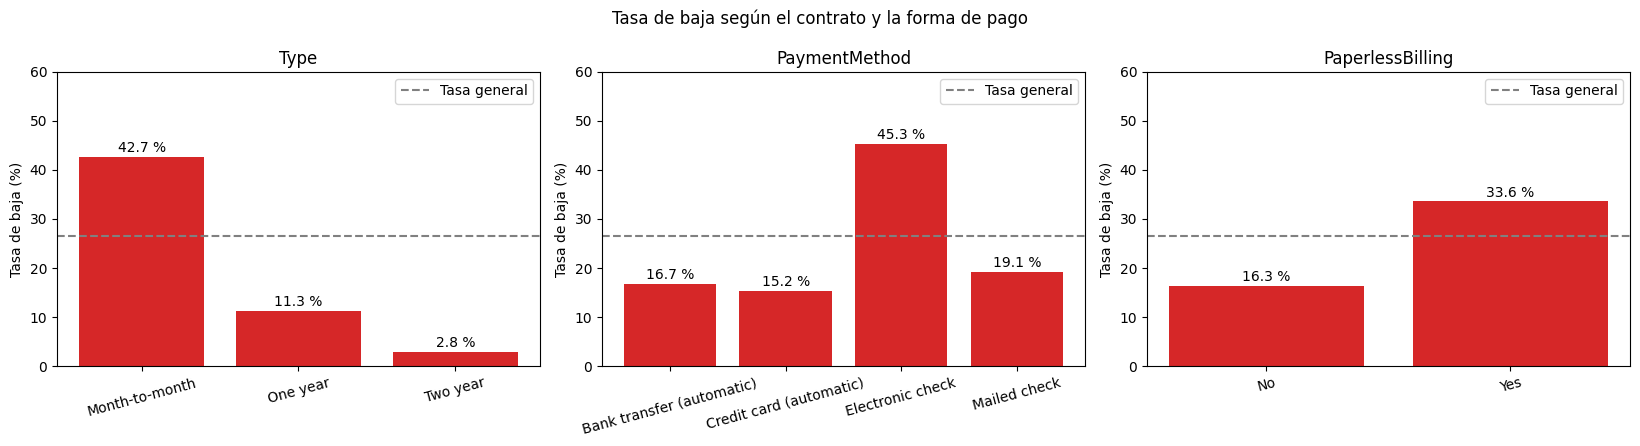

In [34]:
graficar_tasa_baja(columnas_contrato, 1, 3, 'Tasa de baja según el contrato y la forma de pago')

### 3.4 Servicios contratados

In [35]:
# ahora vamos a ver la tasa de baja según los servicios que tiene el cliente
columnas_servicios_eda = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                          'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines', 'tiene_telefono']
tabla_tasa_baja(columnas_servicios_eda)

                 tasa_baja_%  clientes
InternetService                       
DSL                     19.0      2421
Fiber optic             41.9      3096
No                       7.4      1526

                tasa_baja_%  clientes
OnlineSecurity                       
No                     31.3      5024
Yes                    14.6      2019

              tasa_baja_%  clientes
OnlineBackup                       
No                   29.2      4614
Yes                  21.5      2429

                  tasa_baja_%  clientes
DeviceProtection                       
No                       28.7      4621
Yes                      22.5      2422

             tasa_baja_%  clientes
TechSupport                       
No                  31.2      4999
Yes                 15.2      2044

             tasa_baja_%  clientes
StreamingTV                       
No                  24.3      4336
Yes                 30.1      2707

                 tasa_baja_%  clientes
StreamingMovies         

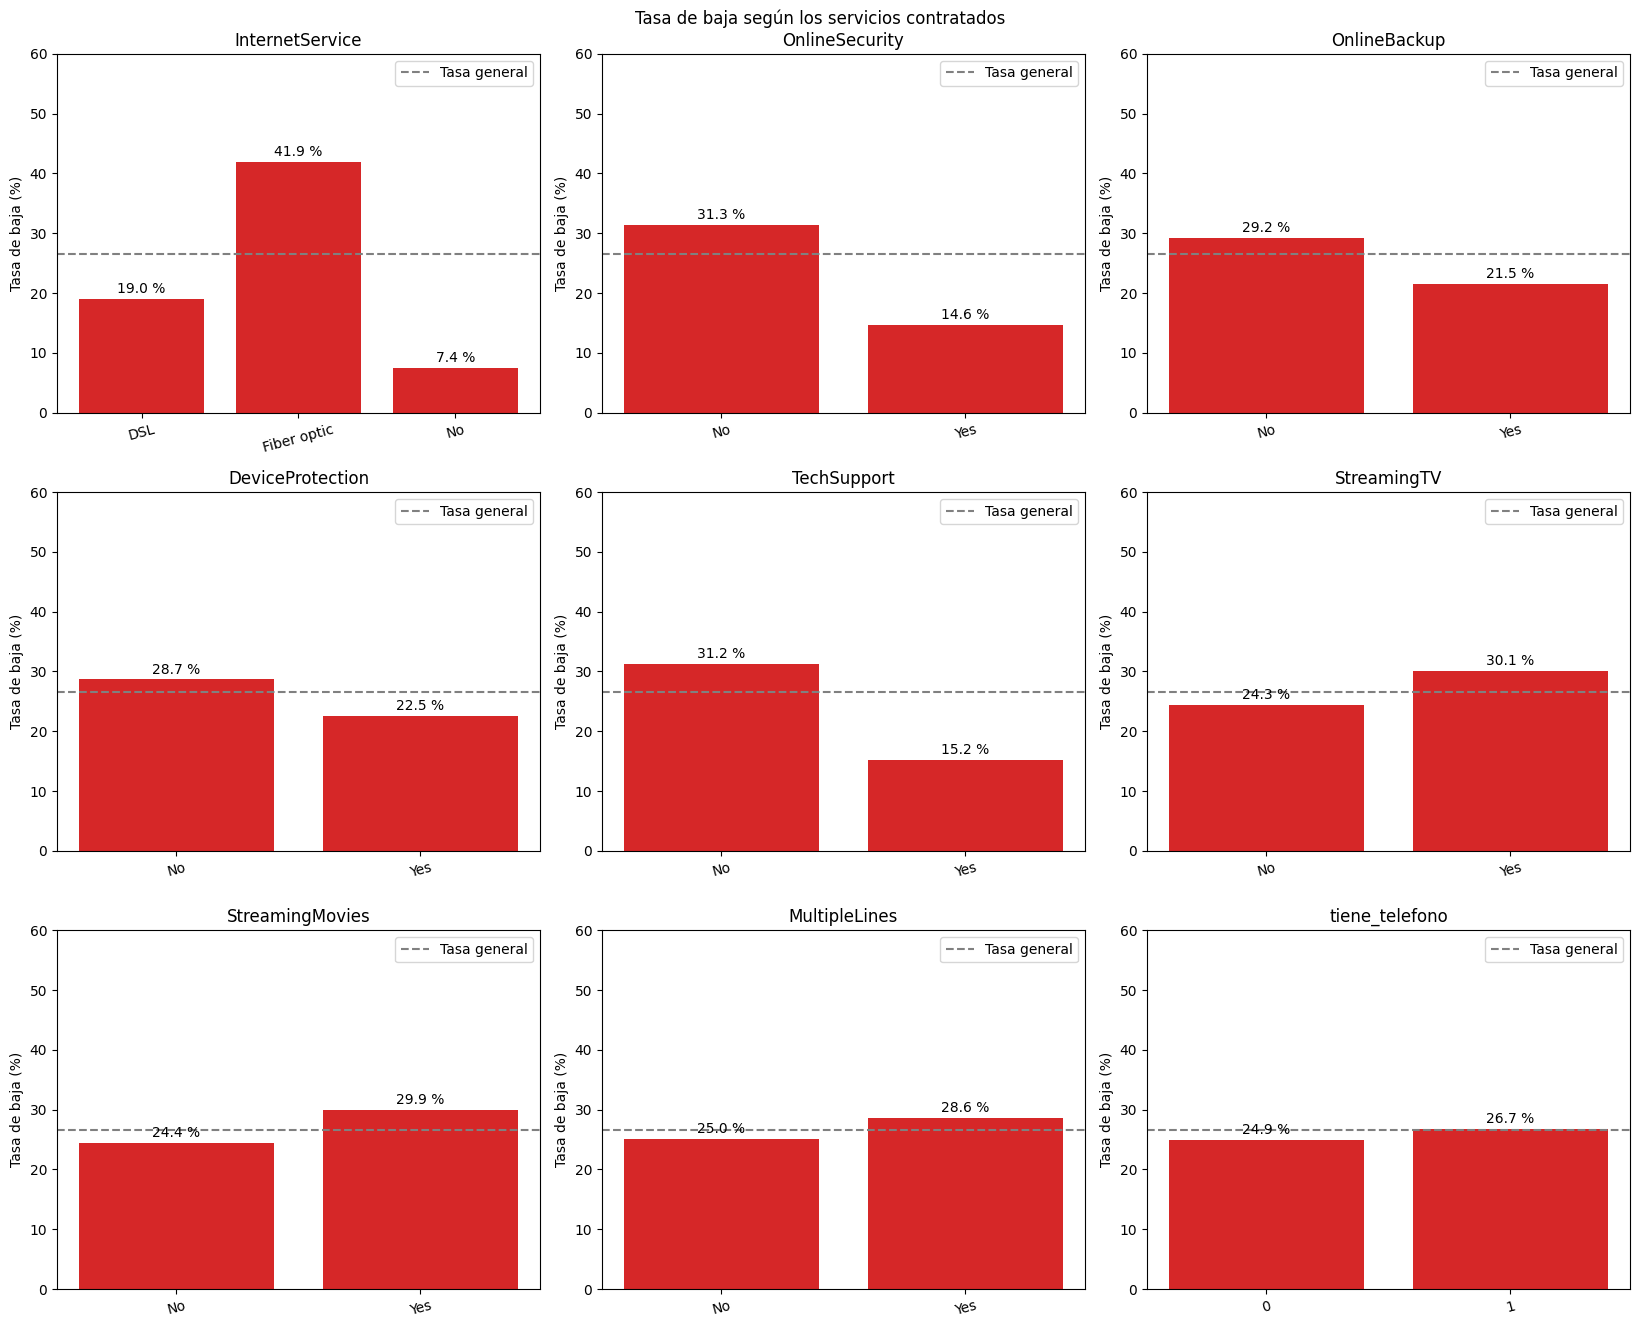

In [36]:
graficar_tasa_baja(columnas_servicios_eda, 3, 3, 'Tasa de baja según los servicios contratados')

### 3.5 Datos personales

In [37]:
# ahora vamos a ver la tasa de baja según los datos personales del cliente
columnas_personales = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']
tabla_tasa_baja(columnas_personales)

        tasa_baja_%  clientes
gender                       
Female         26.9      3488
Male           26.2      3555

               tasa_baja_%  clientes
SeniorCitizen                       
0                     23.6      5901
1                     41.7      1142

         tasa_baja_%  clientes
Partner                       
No              33.0      3641
Yes             19.7      3402

            tasa_baja_%  clientes
Dependents                       
No                 31.3      4933
Yes                15.5      2110



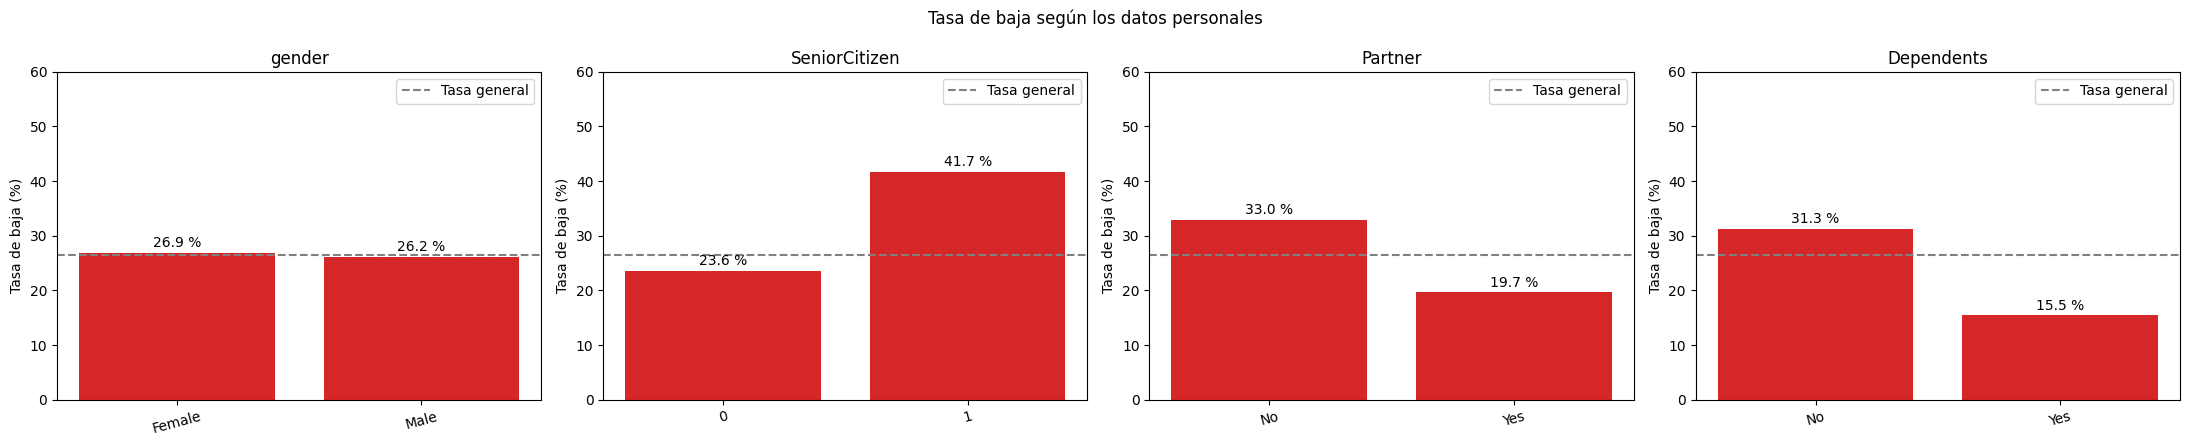

In [38]:
graficar_tasa_baja(columnas_personales, 1, 4, 'Tasa de baja según los datos personales')

### 3.6 Relación entre las columnas numéricas

In [39]:
# ahora vamos a ver la correlación entre las columnas numéricas y con el objetivo
datos[['MonthlyCharges', 'TotalCharges', 'antiguedad_meses', 'baja']].corr().round(2)

,MonthlyCharges,TotalCharges,antiguedad_meses,baja
MonthlyCharges,1.00,0.65,0.25,0.19
TotalCharges,0.65,1.00,0.83,-0.20
antiguedad_meses,0.25,0.83,1.00,-0.35
baja,0.19,-0.20,-0.35,1.00


**Conclusión**

Con el análisis pude ver el estado de la compañía y el perfil de los clientes que se van:

- En los últimos cuatro meses de los datos, de octubre de 2019 a enero de 2020, la compañía perdió en promedio 467.2 clientes por mes y ganó 231.8. Se van cerca del doble de los que entran, con un saldo negativo de entre 221 y 248 clientes cada mes. Las bajas de los cuatro meses son parecidas, entre 458 y 485, así que con estos datos no puedo afirmar que las bajas estén creciendo mes a mes, pero sí que la compañía está perdiendo clientes.
- La antigüedad es lo que más separa a los dos grupos. Los clientes que se fueron tienen una mediana de 10 meses de antigüedad y los activos de 38. Entre los 1481 clientes con 6 meses o menos se fue el 52.9 %, y entre los 2239 con más de 48 meses solo el 9.5 %. En el histograma se ve que las bajas se concentran en los primeros meses.
- Los clientes que se van pagan más por mes: su mediana de cargo mensual es 79.6 contra 64.4 de los activos. Entre los activos hay un grupo grande que paga alrededor de 20, y en ese rango casi no hay bajas.
- El tipo de contrato marca una diferencia grande. Con contrato mes a mes se va el 42.7 %, con contrato de un año el 11.3 % y con el de dos años el 2.8 %.
- En la forma de pago destaca el cheque electrónico, con 45.3 % de bajas, mientras los otros tres métodos están entre 15.2 % y 19.1 %. Los clientes con factura electrónica también se van más, 33.6 % contra 16.3 %.
- En los servicios, los clientes de fibra óptica se van mucho más (41.9 %) que los de DSL (19.0 %) y los que no tienen internet (7.4 %). Tener seguridad en línea o soporte técnico va junto a menos bajas: 14.6 % y 15.2 %, contra 31.3 % y 31.2 % de quienes no los tienen. El respaldo en línea y la protección de dispositivos van en la misma dirección pero con menos diferencia. Los servicios de streaming y las líneas múltiples cambian poco la tasa, entre 3 y 6 puntos.
- En los datos personales, los adultos mayores se van más (41.7 % contra 23.6 %), y los clientes con pareja o con dependientes se van menos (19.7 % y 15.5 %, contra 33.0 % y 31.3 %).
- Hay dos columnas que no separan a los grupos. En `gender` la tasa es 26.9 % para mujeres y 26.2 % para hombres, y en `tiene_telefono` es 26.7 % con teléfono y 24.9 % sin teléfono. Las dos están pegadas a la tasa general de 26.5 %.
- `TotalCharges` tiene una correlación de 0.83 con `antiguedad_meses`, lo que tiene sentido porque el cargo total es más o menos el cargo mensual acumulado durante los meses que el cliente lleva. Las dos columnas le dan al modelo información muy parecida.

En resumen, el cliente con más riesgo de irse es nuevo, tiene contrato mes a mes, paga un cargo mensual alto, usa fibra óptica sin servicios de seguridad ni soporte y paga con cheque electrónico. Esto nos da una idea del perfil del cliente que suele dejar con más frecuencia la compañía.

Para el modelado me llevo dos pendientes. Voy a comprobar si `TotalCharges` aporta algo teniendo ya la antigüedad y el cargo mensual, y si vale la pena conservar `gender`, comparando el modelo con y sin esas columnas en lugar de eliminarlas ahora.

## 4. Modelado

**Objetivo**

Entrenar un modelo que prediga si un cliente se dará de baja. Empiezo con una regresión logística, porque es un modelo simple y fácil de explicar al equipo de marketing, y la comparo con una línea base, un bosque aleatorio y LightGBM para comprobar si un modelo más complejo mejora el resultado.

Como solo el 26.5 % de los clientes se dio de baja, la exactitud sola no sirve para evaluar. Uso AUC-ROC como métrica principal, porque mide qué tan bien ordena el modelo a los clientes según su riesgo, y la acompaño con F1, recall y exactitud. El recall me interesa en especial porque indica qué parte de las bajas reales logra detectar el modelo.

### 4.1 Preparación de los datos

In [40]:
# Vamos a quitar las columnas que no sirven como características:
# customerID es un identificador, y las fechas ya están resumidas en antiguedad_meses
# además, EndDate y fecha_fin contienen la respuesta que queremos predecir
datos_modelo = datos.drop(['customerID', 'BeginDate', 'EndDate', 'fecha_fin'], axis=1)

# ahora vamos a codificar las columnas categóricas con OHE,
# drop_first=True quita una columna por categoría para no repetir información
datos_modelo = pd.get_dummies(datos_modelo, drop_first=True)

print('Filas y columnas:', datos_modelo.shape)
print(list(datos_modelo.columns))

Filas y columnas: (7043, 24)
['MonthlyCharges', 'TotalCharges', 'baja', 'antiguedad_meses', 'SeniorCitizen', 'tiene_telefono', 'Type_One year', 'Type_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'MultipleLines_Yes']


In [41]:
# ahora vamos a separar las características del objetivo
features = datos_modelo.drop('baja', axis=1)
target = datos_modelo['baja']

# ahora vamos a dividir en entrenamiento (60 %), validación (20 %) y prueba (20 %),
# con stratify para que los tres conjuntos tengan la misma proporción de bajas
features_train, features_rest, target_train, target_rest = train_test_split(
    features, target, test_size=0.4, random_state=12345, stratify=target)
features_valid, features_test, target_valid, target_test = train_test_split(
    features_rest, target_rest, test_size=0.5, random_state=12345, stratify=target_rest)

print('Entrenamiento:', features_train.shape, 'proporción de bajas:', round(target_train.mean(), 3))
print('Validación:', features_valid.shape, 'proporción de bajas:', round(target_valid.mean(), 3))
print('Prueba:', features_test.shape, 'proporción de bajas:', round(target_test.mean(), 3))

Entrenamiento: (4225, 23) proporción de bajas: 0.265
Validación: (1409, 23) proporción de bajas: 0.265
Prueba: (1409, 23) proporción de bajas: 0.265


In [42]:
# ahora vamos a escalar las columnas numéricas, porque la regresión logística
# es sensible a que unas columnas tengan valores mucho más grandes que otras
# el escalador se ajusta solo con el conjunto de entrenamiento
pd.options.mode.chained_assignment = None

columnas_numericas = ['MonthlyCharges', 'TotalCharges', 'antiguedad_meses']

scaler = StandardScaler()
scaler.fit(features_train[columnas_numericas])

features_train[columnas_numericas] = scaler.transform(features_train[columnas_numericas])
features_valid[columnas_numericas] = scaler.transform(features_valid[columnas_numericas])
features_test[columnas_numericas] = scaler.transform(features_test[columnas_numericas])

features_train[columnas_numericas].describe().round(2)

,MonthlyCharges,TotalCharges,antiguedad_meses
count,4225.00,4225.00,4225.00
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.54,-1.02,-1.33
25%,-0.98,-0.84,-0.97
50%,0.18,-0.39,-0.12
75%,0.83,0.70,0.94
max,1.78,2.73,1.59


In [43]:
# ahora vamos a crear una función que calcula las cuatro métricas de un modelo ya entrenado
def evaluar_modelo(modelo, features, target):
    predicciones = modelo.predict(features)
    probabilidades = modelo.predict_proba(features)[:, 1]
    auc_roc = roc_auc_score(target, probabilidades)
    f1 = f1_score(target, predicciones)
    recall = recall_score(target, predicciones)
    exactitud = accuracy_score(target, predicciones)
    return [round(auc_roc, 4), round(f1, 3), round(recall, 3), round(exactitud, 3)]

### 4.2 Línea base

In [44]:
# ahora vamos a medir un modelo que siempre predice que el cliente no se va (clase 0)
predicciones_base = pd.Series(0, index=target_valid.index)

exactitud_base = accuracy_score(target_valid, predicciones_base)
recall_base = recall_score(target_valid, predicciones_base)
# para el AUC-ROC le damos a todos los clientes la misma probabilidad
auc_roc_base = roc_auc_score(target_valid, predicciones_base)

print('Exactitud:', round(exactitud_base, 3))
print('Recall:', round(recall_base, 3))
print('AUC-ROC:', round(auc_roc_base, 4))

# el F1 es 0 porque este modelo no detecta ninguna baja
resultado_base = [round(auc_roc_base, 4), 0.0, round(recall_base, 3), round(exactitud_base, 3)]

Exactitud: 0.735
Recall: 0.0
AUC-ROC: 0.5


### 4.3 Regresión logística

In [45]:
# ahora vamos a entrenar la regresión logística con todas las características,
# class_weight='balanced' le da más peso a las bajas, que son la clase con menos clientes
modelo = LogisticRegression(random_state=12345, class_weight='balanced', solver='liblinear')
modelo.fit(features_train, target_train)

resultado = evaluar_modelo(modelo, features_valid, target_valid)
print('AUC-ROC:', resultado[0])
print('F1:', resultado[1])
print('Recall:', resultado[2])
print('Exactitud:', resultado[3])

AUC-ROC: 0.8353
F1: 0.605
Recall: 0.802
Exactitud: 0.722


In [46]:
# en el análisis exploratorio quedaron dos columnas en duda: TotalCharges y gender
# ahora vamos a entrenar el mismo modelo quitando cada una y las dos, para medir cuánto aportan
opciones = [[], ['gender_Male'], ['TotalCharges'], ['TotalCharges', 'gender_Male']]
nombres_opciones = ['Todas las columnas', 'Sin gender', 'Sin TotalCharges', 'Sin TotalCharges ni gender']

filas = []
for i, columnas_quitar in enumerate(opciones):
    modelo = LogisticRegression(random_state=12345, class_weight='balanced', solver='liblinear')
    modelo.fit(features_train.drop(columnas_quitar, axis=1), target_train)
    resultado = evaluar_modelo(modelo, features_valid.drop(columnas_quitar, axis=1), target_valid)
    filas.append(resultado)

comparacion_columnas = pd.DataFrame(filas, index=nombres_opciones,
                                    columns=['AUC-ROC', 'F1', 'Recall', 'Exactitud'])
comparacion_columnas

,AUC-ROC,F1,Recall,Exactitud
Todas las columnas,0.8353,0.605,0.802,0.722
Sin gender,0.8353,0.609,0.807,0.725
Sin TotalCharges,0.8344,0.608,0.799,0.726
Sin TotalCharges ni gender,0.8346,0.613,0.805,0.730


In [47]:
# ahora vamos a calcular cuánto cambia el AUC-ROC al quitar las dos columnas
auc_todas = comparacion_columnas.loc['Todas las columnas', 'AUC-ROC']
auc_sin_ambas = comparacion_columnas.loc['Sin TotalCharges ni gender', 'AUC-ROC']
print('Diferencia de AUC-ROC al quitar las dos columnas:', round(auc_sin_ambas - auc_todas, 4))

Diferencia de AUC-ROC al quitar las dos columnas: -0.0007


**Nota sobre `TotalCharges` y `gender`**

Voy a eliminar estas dos columnas antes de seguir con los demás modelos. La tabla anterior muestra que la regresión logística funciona igual sin ellas: el AUC-ROC pasa de 0.8353 con todas las columnas a 0.8346 sin las dos, una diferencia de 0.0007, y el F1 incluso sube de 0.605 a 0.613.

Esto coincide con lo que vi en el análisis exploratorio. `gender` no separa a los clientes, porque la tasa de baja es casi la misma en mujeres y hombres. `TotalCharges` repite información que ya está en `antiguedad_meses` y `MonthlyCharges`, con una correlación de 0.83 con la antigüedad. Prefiero un modelo con menos columnas que dé el mismo resultado, porque es más fácil de explicar y cada coeficiente se puede leer sin que dos columnas se repartan el mismo efecto.

In [48]:
# ahora vamos a eliminar las dos columnas de los tres conjuntos
columnas_eliminar = ['TotalCharges', 'gender_Male']

features_train = features_train.drop(columnas_eliminar, axis=1)
features_valid = features_valid.drop(columnas_eliminar, axis=1)
features_test = features_test.drop(columnas_eliminar, axis=1)

print('Entrenamiento:', features_train.shape)
print('Validación:', features_valid.shape)
print('Prueba:', features_test.shape)

Entrenamiento: (4225, 21)
Validación: (1409, 21)
Prueba: (1409, 21)


In [49]:
# ahora vamos a entrenar la regresión logística definitiva, ya sin esas dos columnas
modelo_logistica = LogisticRegression(random_state=12345, class_weight='balanced', solver='liblinear')
modelo_logistica.fit(features_train, target_train)

resultado_logistica = evaluar_modelo(modelo_logistica, features_valid, target_valid)
print('AUC-ROC:', resultado_logistica[0])
print('F1:', resultado_logistica[1])
print('Recall:', resultado_logistica[2])
print('Exactitud:', resultado_logistica[3])

AUC-ROC: 0.8346
F1: 0.613
Recall: 0.805
Exactitud: 0.73


### 4.4 Bosque aleatorio

In [50]:
# ahora vamos a probar el bosque aleatorio con varias profundidades y cantidades de árboles,
# y nos quedamos con la combinación de mejor AUC-ROC en validación
mejor_auc_bosque = 0
resultado_bosque = []

for profundidad in [4, 6, 8, 10, 12]:
    for arboles in [50, 100, 200]:
        modelo = RandomForestClassifier(random_state=12345, n_estimators=arboles,
                                        max_depth=profundidad, class_weight='balanced')
        modelo.fit(features_train, target_train)
        resultado = evaluar_modelo(modelo, features_valid, target_valid)
        print('profundidad:', profundidad, 'árboles:', arboles, 'AUC-ROC:', resultado[0])
        if resultado[0] > mejor_auc_bosque:
            mejor_auc_bosque = resultado[0]
            resultado_bosque = resultado
            mejor_profundidad = profundidad
            mejores_arboles = arboles

print()
print('Mejor bosque: profundidad', mejor_profundidad, 'y', mejores_arboles, 'árboles')
print('AUC-ROC:', resultado_bosque[0], 'F1:', resultado_bosque[1],
      'Recall:', resultado_bosque[2], 'Exactitud:', resultado_bosque[3])

profundidad: 4 árboles: 50 AUC-ROC: 0.8308


profundidad: 4 árboles: 100 AUC-ROC: 0.8317


profundidad: 4 árboles: 200 AUC-ROC: 0.832
profundidad: 6 árboles: 50 AUC-ROC: 0.833


profundidad: 6 árboles: 100 AUC-ROC: 0.8345


profundidad: 6 árboles: 200 AUC-ROC: 0.834
profundidad: 8 árboles: 50 AUC-ROC: 0.8311


profundidad: 8 árboles: 100 AUC-ROC: 0.8324


profundidad: 8 árboles: 200 AUC-ROC: 0.8329
profundidad: 10 árboles: 50 AUC-ROC: 0.8253


profundidad: 10 árboles: 100 AUC-ROC: 0.8281


profundidad: 10 árboles: 200 AUC-ROC: 0.8302
profundidad: 12 árboles: 50 AUC-ROC: 0.8246


profundidad: 12 árboles: 100 AUC-ROC: 0.8278


profundidad: 12 árboles: 200 AUC-ROC: 0.8276

Mejor bosque: profundidad 6 y 100 árboles
AUC-ROC: 0.8345 F1: 0.608 Recall: 0.816 Exactitud: 0.72


### 4.5 LightGBM

In [51]:
# ahora vamos a probar LightGBM con varias tasas de aprendizaje y cantidades de árboles
mejor_auc_lgbm = 0
resultado_lgbm = []

for tasa in [0.05, 0.1]:
    for arboles in [50, 100, 200, 300]:
        modelo = LGBMClassifier(random_state=12345, n_estimators=arboles, learning_rate=tasa,
                                num_leaves=8, class_weight='balanced', verbose=-1)
        modelo.fit(features_train, target_train)
        resultado = evaluar_modelo(modelo, features_valid, target_valid)
        print('tasa:', tasa, 'árboles:', arboles, 'AUC-ROC:', resultado[0])
        if resultado[0] > mejor_auc_lgbm:
            mejor_auc_lgbm = resultado[0]
            resultado_lgbm = resultado
            mejor_tasa = tasa
            mejores_arboles_lgbm = arboles

print()
print('Mejor LightGBM: tasa', mejor_tasa, 'y', mejores_arboles_lgbm, 'árboles')
print('AUC-ROC:', resultado_lgbm[0], 'F1:', resultado_lgbm[1],
      'Recall:', resultado_lgbm[2], 'Exactitud:', resultado_lgbm[3])

tasa: 0.05 árboles: 50 AUC-ROC: 0.8307


tasa: 0.05 árboles: 100 AUC-ROC: 0.8326


tasa: 0.05 árboles: 200 AUC-ROC: 0.8321


tasa: 0.05 árboles: 300 AUC-ROC: 0.8298
tasa: 0.1 árboles: 50 AUC-ROC: 0.833
tasa: 0.1 árboles: 100 AUC-ROC: 0.8309


tasa: 0.1 árboles: 200 AUC-ROC: 0.8272


tasa: 0.1 árboles: 300 AUC-ROC: 0.8225

Mejor LightGBM: tasa 0.1 y 50 árboles
AUC-ROC: 0.833 F1: 0.614 Recall: 0.813 Exactitud: 0.729


### 4.6 Comparación y elección del modelo

In [52]:
# ahora vamos a reunir los resultados de validación de todos los modelos en una tabla
comparacion_modelos = pd.DataFrame(
    [resultado_base, resultado_logistica, resultado_bosque, resultado_lgbm],
    index=['Línea base', 'Regresión logística', 'Bosque aleatorio', 'LightGBM'],
    columns=['AUC-ROC', 'F1', 'Recall', 'Exactitud'])
comparacion_modelos

,AUC-ROC,F1,Recall,Exactitud
Línea base,0.5000,0.000,0.000,0.735
Regresión logística,0.8346,0.613,0.805,0.730
Bosque aleatorio,0.8345,0.608,0.816,0.720
LightGBM,0.8330,0.614,0.813,0.729


**Conclusión**

Preparé los datos, entrené cuatro modelos y los comparé en el conjunto de validación:

- Después de la codificación quedaron 23 características. Dividí los datos en 4225 clientes para entrenamiento, 1409 para validación y 1409 para prueba, y los tres conjuntos conservan el 26.5 % de bajas gracias a `stratify`. Escalé las columnas numéricas ajustando el escalador solo con el conjunto de entrenamiento, para no usar información de validación ni de prueba.
- La línea base, que siempre predice que el cliente no se va, tiene una exactitud de 0.735 pero un recall de 0 y un AUC-ROC de 0.5. Acierta en casi tres de cada cuatro clientes sin detectar ninguna baja, por eso la exactitud no me sirve como métrica principal en este proyecto.
- La regresión logística con todas las columnas obtuvo un AUC-ROC de 0.8353. Al quitar `gender` el AUC-ROC no cambia (0.8353), al quitar `TotalCharges` baja a 0.8344, y sin las dos queda en 0.8346. La diferencia entre usar todas y quitar las dos es de 0.0007, así que decidí eliminarlas. `gender` no separa a los clientes y `TotalCharges` repite lo que ya dicen la antigüedad y el cargo mensual, como había visto en el análisis exploratorio. El modelo quedó con 21 características.
- La regresión logística definitiva obtuvo un AUC-ROC de 0.8346, un F1 de 0.613, un recall de 0.805 y una exactitud de 0.730. El recall indica que detecta cerca de 8 de cada 10 clientes que se dan de baja.
- El mejor bosque aleatorio, con profundidad 6 y 100 árboles, llegó a un AUC-ROC de 0.8345, con F1 de 0.608 y recall de 0.816. Con más profundidad el resultado empeora, hasta 0.8246 con profundidad 12.
- El mejor LightGBM, con tasa de aprendizaje 0.1 y 50 árboles, llegó a un AUC-ROC de 0.8330, con F1 de 0.614 y recall de 0.813. Al agregar más árboles también empeora, hasta 0.8225 con 300 árboles.
- Los tres modelos quedan prácticamente empatados: el AUC-ROC va de 0.8330 a 0.8346 y el F1 de 0.608 a 0.614. Los modelos más complejos no mejoran a la regresión logística.

Elijo la regresión logística como modelo final. Da el mismo resultado que el bosque aleatorio y que LightGBM, es el modelo más simple de los tres y sus coeficientes permiten explicarle al equipo de marketing qué características aumentan o reducen el riesgo de baja. En la siguiente etapa la evalúo con el conjunto de prueba, que no usé hasta ahora para ninguna decisión.

## 5. Prueba final

**Objetivo**

Comprobar cómo se comporta la regresión logística con clientes que no vio durante el entrenamiento ni durante la elección del modelo. Antes de usar el conjunto de prueba reviso en validación el umbral de decisión. Después evalúo el modelo en prueba, traduzco sus aciertos y errores a número de clientes, y reviso los coeficientes para explicar qué características aumentan o reducen el riesgo de baja.

### 5.1 Umbral de decisión

In [53]:
# el modelo calcula una probabilidad de baja y por defecto marca como baja a quien supera 0.5
# ahora vamos a probar otros umbrales en validación para ver cómo cambian las métricas
probabilidades_valid = modelo_logistica.predict_proba(features_valid)[:, 1]

filas = []
for umbral in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]:
    predicciones = (probabilidades_valid > umbral).astype(int)
    f1 = f1_score(target_valid, predicciones)
    recall = recall_score(target_valid, predicciones)
    precision = precision_score(target_valid, predicciones)
    marcados = predicciones.sum()
    filas.append([umbral, round(f1, 3), round(recall, 3), round(precision, 3), marcados])

tabla_umbrales = pd.DataFrame(filas, columns=['Umbral', 'F1', 'Recall', 'Precisión', 'Clientes marcados'])
print('Clientes en validación:', len(target_valid), '| bajas reales:', target_valid.sum())
tabla_umbrales

Clientes en validación: 1409 | bajas reales: 374


,Umbral,F1,Recall,Precisión,Clientes marcados
0,0.30,0.568,0.928,0.410,847
1,0.35,0.582,0.909,0.428,795
2,0.40,0.582,0.853,0.442,722
3,0.45,0.598,0.826,0.468,660
4,0.50,0.613,0.805,0.495,608
5,0.55,0.610,0.746,0.516,541
6,0.60,0.608,0.693,0.542,478
7,0.65,0.599,0.642,0.561,428
8,0.70,0.602,0.610,0.595,383


### 5.2 Evaluación en el conjunto de prueba

In [54]:
# ahora vamos a evaluar el modelo final en el conjunto de prueba, con el umbral de 0.5
resultado_prueba = evaluar_modelo(modelo_logistica, features_test, target_test)

# también medimos la línea base en prueba, el modelo que siempre predice que el cliente no se va
predicciones_base_prueba = pd.Series(0, index=target_test.index)
exactitud_base_prueba = accuracy_score(target_test, predicciones_base_prueba)
# igual que antes, el F1 y el recall de la línea base son 0 porque no detecta ninguna baja
resultado_base_prueba = [0.5, 0.0, 0.0, round(exactitud_base_prueba, 3)]

comparacion_prueba = pd.DataFrame(
    [resultado_logistica, resultado_prueba, resultado_base_prueba],
    index=['Regresión logística en validación', 'Regresión logística en prueba', 'Línea base en prueba'],
    columns=['AUC-ROC', 'F1', 'Recall', 'Exactitud'])
comparacion_prueba

,AUC-ROC,F1,Recall,Exactitud
Regresión logística en validación,0.8346,0.613,0.805,0.730
Regresión logística en prueba,0.8396,0.625,0.781,0.752
Línea base en prueba,0.5000,0.000,0.000,0.735


### 5.3 Matriz de confusión

In [55]:
# ahora vamos a ver los aciertos y los errores del modelo en número de clientes
predicciones_prueba = modelo_logistica.predict(features_test)
matriz = confusion_matrix(target_test, predicciones_prueba)
print(matriz)
print()

activos_bien = matriz[0][0]
falsas_alarmas = matriz[0][1]
bajas_no_detectadas = matriz[1][0]
bajas_detectadas = matriz[1][1]

print('Clientes en prueba:', len(target_test))
print('Bajas reales:', target_test.sum())
print('  bajas detectadas:', bajas_detectadas)
print('  bajas no detectadas:', bajas_no_detectadas)
print('Clientes activos:', len(target_test) - target_test.sum())
print('  bien clasificados:', activos_bien)
print('  falsas alarmas:', falsas_alarmas)
print()
print('Clientes marcados como baja:', bajas_detectadas + falsas_alarmas)
print('Precisión:', round(precision_score(target_test, predicciones_prueba), 3))

[[767 268]
 [ 82 292]]

Clientes en prueba: 1409
Bajas reales: 374
  bajas detectadas: 292
  bajas no detectadas: 82
Clientes activos: 1035
  bien clasificados: 767
  falsas alarmas: 268

Clientes marcados como baja: 560
Precisión: 0.521


### 5.4 Curva ROC

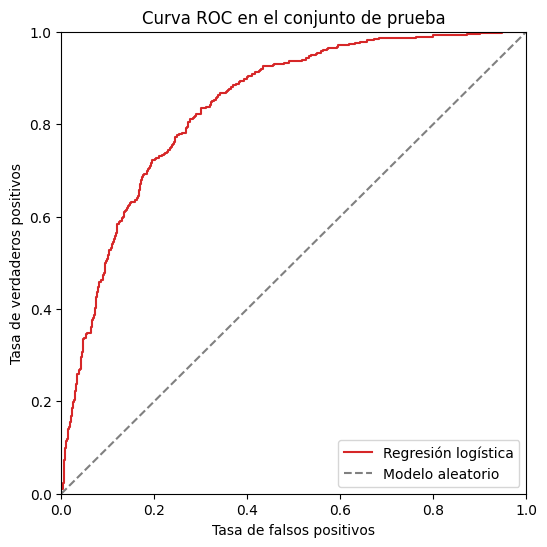

AUC-ROC en prueba: 0.8396


In [56]:
# ahora vamos a dibujar la curva ROC del modelo en el conjunto de prueba
probabilidades_prueba = modelo_logistica.predict_proba(features_test)[:, 1]
fpr, tpr, umbrales = roc_curve(target_test, probabilidades_prueba)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color='tab:red', label='Regresión logística')
# la diagonal es un modelo que responde al azar
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Modelo aleatorio')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title('Curva ROC en el conjunto de prueba')
ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos')
ax.legend()
plt.show()

print('AUC-ROC en prueba:', round(roc_auc_score(target_test, probabilidades_prueba), 4))

### 5.5 Coeficientes del modelo

In [57]:
# ahora vamos a ver los coeficientes de la regresión logística, ordenados de menor a mayor
# un coeficiente positivo aumenta el riesgo de baja y uno negativo lo reduce
coeficientes = pd.Series(modelo_logistica.coef_[0], index=features_train.columns)
coeficientes = coeficientes.sort_values()
print(coeficientes.round(2))

Type_Two year                           -1.34
antiguedad_meses                        -0.88
InternetService_No                      -0.69
Type_One year                           -0.54
tiene_telefono                          -0.40
OnlineSecurity_Yes                      -0.37
TechSupport_Yes                         -0.35
Dependents_Yes                          -0.26
PaymentMethod_Mailed check              -0.16
OnlineBackup_Yes                        -0.13
PaymentMethod_Credit card (automatic)   -0.12
DeviceProtection_Yes                    -0.09
Partner_Yes                             -0.05
MonthlyCharges                           0.07
SeniorCitizen                            0.20
MultipleLines_Yes                        0.24
PaperlessBilling_Yes                     0.24
PaymentMethod_Electronic check           0.30
StreamingTV_Yes                          0.32
StreamingMovies_Yes                      0.36
InternetService_Fiber optic              0.86
dtype: float64


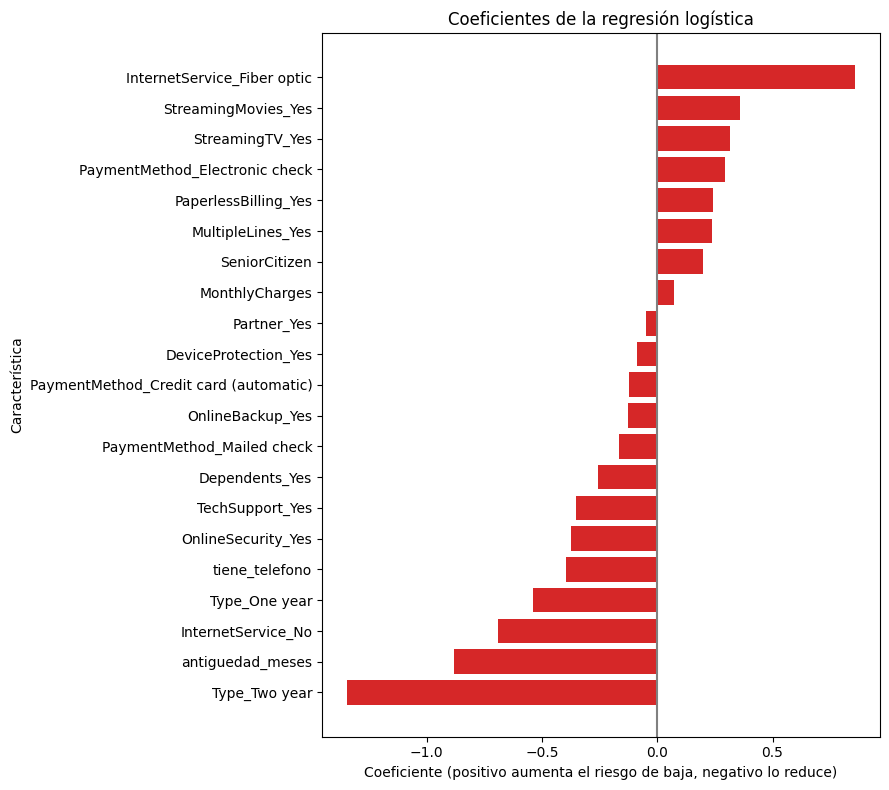

In [58]:
# ahora vamos a graficar los coeficientes
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(coeficientes.index, coeficientes.values, color='tab:red')
ax.axvline(0, color='gray')
ax.set_title('Coeficientes de la regresión logística')
ax.set_xlabel('Coeficiente (positivo aumenta el riesgo de baja, negativo lo reduce)')
ax.set_ylabel('Característica')
plt.tight_layout()
plt.show()

**Conclusión**

Evalué la regresión logística con el conjunto de prueba, que no había usado para ninguna decisión:

- Antes de la prueba revisé el umbral de decisión en validación. El umbral de 0.5 da el F1 más alto, 0.613, así que lo mantuve. La tabla muestra el intercambio que hay al moverlo: con 0.3 el recall sube a 0.928 pero el modelo marca a 847 de los 1409 clientes y la precisión baja a 0.410, y con 0.7 la precisión sube a 0.595 pero el recall cae a 0.610 y solo marca a 383 clientes.
- En prueba el modelo obtuvo un AUC-ROC de 0.8396, un F1 de 0.625, un recall de 0.781 y una exactitud de 0.752. Son valores muy parecidos a los de validación (0.8346, 0.613, 0.805 y 0.730), así que el modelo se comporta igual con clientes nuevos y no está sobreajustado.
- La línea base en prueba tiene una exactitud de 0.735 y un AUC-ROC de 0.5. El modelo la supera en exactitud por poco, 0.752, pero la diferencia real está en que la línea base no detecta ninguna baja y el modelo detecta la mayoría.
- De las 374 bajas reales del conjunto de prueba, el modelo detectó 292, el 78.1 %, y se le escaparon 82. De los 1035 clientes activos clasificó bien a 767 y marcó por error a 268, el 25.9 %.
- En total el modelo marcó a 560 clientes como posibles bajas y 292 lo eran, una precisión de 0.521. Es decir, cerca de la mitad de las promociones llegarían a clientes que de verdad se iban a ir y la otra mitad a clientes que se iban a quedar.
- La curva ROC queda claramente por encima de la diagonal del modelo aleatorio en todo el recorrido.
- Los coeficientes coinciden con lo que vi en el análisis exploratorio. Lo que más reduce el riesgo de baja es el contrato de dos años (-1.34), la antigüedad (-0.88), no tener internet (-0.69) y el contrato de un año (-0.54). También lo reducen la seguridad en línea (-0.37) y el soporte técnico (-0.35). Lo que más lo aumenta es la fibra óptica (0.86), seguida del streaming de películas (0.36) y de TV (0.32) y del pago con cheque electrónico (0.30).
- El cargo mensual tiene un coeficiente pequeño, 0.07, aunque en el análisis exploratorio los clientes que se iban pagaban más. Entiendo que es porque el cargo alto viene de tener fibra óptica y servicios adicionales, y esas columnas ya recogen el efecto.

## Conclusiones generales

El objetivo del proyecto era construir un modelo que le indique a Interconnect qué clientes tienen riesgo de darse de baja, para que el equipo de marketing sepa a quién ofrecerle promociones.

Sobre los datos y el estado de la compañía:

- Trabajé con cuatro tablas que uní en una sola de 7043 clientes. El 26.5 % de ellos, 1869 clientes, se dio de baja.
- En los cuatro meses con bajas registradas, de octubre de 2019 a enero de 2020, la compañía perdió en promedio 467.2 clientes por mes y ganó 231.8. Con solo cuatro meses no puedo decir que las bajas vayan en aumento, pero sí que se van el doble de clientes de los que entran.
- El cliente con más riesgo es nuevo, tiene contrato mes a mes, usa fibra óptica sin seguridad en línea ni soporte técnico y paga con cheque electrónico. Entre los clientes con 6 meses o menos se fue el 52.9 %, y con contrato mes a mes el 42.7 %, contra el 2.8 % con contrato de dos años.

Sobre el modelo:

- Elegí una regresión logística. En validación obtuvo un AUC-ROC de 0.8346, prácticamente igual al del bosque aleatorio (0.8345) y al de LightGBM (0.8330), y es el modelo más simple y el más fácil de explicar.
- Quité `TotalCharges` y `gender` porque el modelo da el mismo resultado sin ellas, con una diferencia de AUC-ROC de 0.0007.
- En el conjunto de prueba el modelo obtuvo un AUC-ROC de 0.8396, un F1 de 0.625 y un recall de 0.781. Detectó 292 de las 374 bajas reales, mientras que un modelo que siempre responde que el cliente se queda no detecta ninguna.
- El modelo también se equivoca: de cada 100 clientes que marca como posible baja, unos 52 se iban a ir y unos 48 no. Además se le escapan cerca de 2 de cada 10 bajas.

Recomendaciones para el equipo de marketing:

- Usar el modelo para decidir a quién ofrecer las promociones. Con el umbral de 0.5 habría que contactar a cerca del 40 % de los clientes (560 de 1409 en prueba) para alcanzar al 78.1 % de los que se van.
- Ajustar el umbral según el costo de la promoción. Si la promoción es barata conviene bajarlo para alcanzar a más clientes en riesgo, y si es cara conviene subirlo para que menos promociones lleguen a clientes que no pensaban irse. La tabla de la sección 5.1 muestra cuántos clientes se marcan con cada umbral.
- Dirigir las promociones a pasar clientes de contrato mes a mes a contratos de uno o dos años, sobre todo en sus primeros meses, que es cuando más se van.
- Revisar el servicio de fibra óptica. Es la característica que más aumenta el riesgo en el modelo y sus clientes se van el doble que los de DSL (41.9 % contra 19.0 %), lo que puede apuntar a un problema de precio o de calidad.
- Ofrecer seguridad en línea y soporte técnico dentro de los planes especiales, porque los clientes que tienen estos servicios se van cerca de la mitad que los que no los tienen.

Una limitación que hay que tener en cuenta es que el modelo muestra qué características van junto a las bajas, pero no demuestra que sean la causa. Por ejemplo, no puedo asegurar que un cliente deje de irse solo por cambiarle el método de pago. Lo recomendable es probar las promociones en un grupo de clientes y comparar sus bajas con las de un grupo que no las reciba.